# PROBLEM STATEMENT
1. Algorithms for vortex panel methods: Write clearly two algorithms, one for constant panel strength and one for linear panel strength.

2. Implementation of your algorithms in python: Write python functions vortex_panel_method_0() and vortex_panel_method_1() to implement your algorithms above. Your functions must have arguments and return data.

3. Verification of your implementations on circular cylinder: Study convergence. Discuss your results briefly.

4. Verification of your implementations on symmetric and non-symmetric airfoils: Study convergence; document effect of number of panels, distribution of panels with different lengths. Discuss your results briefly.

5. Prediction of airfoil characteristics: Use the functions to predict characteristics of one symmetric and one non-symmetric airfoil. Also plot pressure coefficient distributions. Discuss your results briefly

In [79]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

np.random.seed(1)
alpha=5.0
alpha_rad=np.radians(alpha)
v_inf=10

m = np.random.uniform(0.01, 0.06)
p = np.random.uniform(0.20, 0.60)
t = np.random.uniform(0.08, 0.18)

def naca(n):
  n=int(n/2)
  x = np.linspace(0, 1, n)
  yt = 5 * t * ( 0.2969 * np.sqrt(x)- 0.1260 * x- 0.3516 * x**2+ 0.2843 * x**3 - 0.1036 * x**4)
  yc = np.zeros(n)
  dyc_dx = np.zeros(n)
  for i in range(len(x)):
      if x[i] <= p:
          yc[i] = (m / p**2) * (2 * p * x[i] - x[i]**2)
          dyc_dx[i] = (2 * m / p**2) * (p - x[i])
      else:
          yc[i] = (m / (1 - p)**2) * ((1 - 2 * p)+ 2 * p * x[i]- x[i]**2)
          dyc_dx[i] = (2 * m / (1 - p)**2) * ( p - x[i])
  theta = np.arctan(dyc_dx)
  xu = x - yt * np.sin(theta);  yu = yc + yt * np.cos(theta)
  xl = x + yt * np.sin(theta);  yl = yc - yt * np.cos(theta)
  xcurve=np.concatenate((np.flip(xl) , xu[1:]))
  ycurve=np.concatenate((np.flip(yl) , yu[1:]))
  return xcurve,ycurve

The first task here is to plot an airfoil (here plotted a unsymmetric airfoil) . In very initial step we defined the angle of attack . Further if needed we can change it .

For the airfol parameters like mean camber , location of maximum camber ,chord thickness we have used the random seed function in this the values will be chosen at random from the given range of values for m, p,t and after one choice the random seed keeps the valus same for all the re-runs so .

After that the airfoil equations and conditions are written and plotted. We also defined the no of panels function named 'naca'.
But the airfoli that we get through this is generated from leading edge to trailing edge , for our task we need the airfoil to be generated from trailing edge in a clockwise direction . But why in specific clockwise manner only ?? Because when we use the right hand thumb rule we want the normal velocity vector to be facing outward from the surface ,hence we go clockwise from trailing edge . And at trailing edge we apply Kutta condition so therfore the trailing edge as the area of interst

(While solving the equation of airfoil there was a error the airfoil was not completed at the trailing edge i.e. we didnt get a unique crossection point at T.E. so to conquer this problem the coefficient of x^4 is changed to 0.1036 )

In [80]:
def cylinder(r,n):
  theta=np.linspace(2*np.pi, 0, n+1)
  a=r*np.cos(theta)
  b=r*np.sin(theta)
  return a,b


In [81]:

def geometry(xb , yb , v_inf , alpha_rad, verbose=False):
  dx=np.diff(xb)
  dy=np.diff(yb)
  xc=0.5*(xb[:-1] + xb[1:])
  yc=0.5*(yb[:-1] + yb[1:])
  s=np.sqrt(dx**2 + dy**2)
  theta_1=np.arctan2(dy,dx)
  theta_f=theta_1 + np.pi/2
  beta= theta_f - alpha_rad
  v_normal=v_inf*np.cos(beta)
  v_tangent=v_inf*np.sin(beta)
  if verbose:
    print("number of panels:",len(xc))
  return xc,yc,dx,dy,s,theta_1,v_normal,v_tangent

Now if we divide the airfoil very finely that is used more no. of points then we can concentrate all the forces parameters and focus on one point what we call as control point. Therfore we define xc and yc , these are the midpoints of the panels .
But we have just defined the formula , to actually get those points we need to seee at a panel , here there are two end points now in an array of consecutive points if we ignore the two far points of the panel and divide the rest panel by factor of 2 we will get the midpoint which is exactly what we have done by defining xc and yc

Now lets define the panel length , for this we have two components x and y ,so the panel length is the hpotenuse of these two sides.
Now we define the angle . this is the angle w.r.t x-axis that we define by theta.But we have written arctan2 , because arctan2 automatically considers the signs of both dx and dy and gives the correct angle in the correct quadrant.

theta_1 - Panel angle--This calculates the angle made by each panel with the positive horizontal x-axis.

theta_f - Normal angle--represents the direction of the panel's normal vector (for a counterclockwise rotation).

beta - Angle between freestream and normal

Third angle
beta - Relative angle
The use of Beta is to resolve the incoming velocity into two directions:$$Vn=Vinfty*cos(beta)$$$$Vt=Vinfty*sin(beta)$$


so now we have calculated xc, yc, dx,dy, s, theta_1, theta_f, beta ,v_tangent ,v_normal.And we plotted the airfoil , cicular cylinder, divided into panels and also found the results for the velocities for specified no. of panels.



In [82]:
def influence_matrices(xb, yb, xc, yc, s, theta_1):
    N = len(xc)
    A_n = np.zeros((N, N))     # normal velocity influence   (times 1/(2*pi) to get velocity)
    A_t = np.zeros((N, N))     # tangent velocity influence  (times 1/(2*pi) to get velocity)
    for i in range(N):
        for j in range(N):
            if i == j:
                A_t[i, j] = -np.pi          # self term: sheet jump, -gamma/2 on outer side
                continue                    # self normal term is 0 for constant strength
            def d(q):
                return (xc[i]-(xb[j]+q*np.cos(theta_1[j])),
                        yc[i]-(yb[j]+q*np.sin(theta_1[j])))
            def dn(q):
                dx_, dy_ = d(q)
                return (dx_*np.cos(theta_1[i])+dy_*np.sin(theta_1[i]))/(dx_**2+dy_**2)
            def dt(q):
                dx_, dy_ = d(q)
                return (dx_*np.sin(theta_1[i])-dy_*np.cos(theta_1[i]))/(dx_**2+dy_**2)
            A_n[i, j] = quad(dn, 0, s[j])[0]
            A_t[i, j] = quad(dt, 0, s[j])[0]
    return A_n, A_t

In [83]:
def vortex_panel_method_0(N, A_n, A_t, v_normal, v_tangent, v_inf, rcond=5e-3):

    A = np.zeros((N+1, N))
    A[:N, :] = A_n
    A[N, 0] = 1; A[N, N-1] = 1                    # Kutta: gamma_1 + gamma_N = 0
    b = np.zeros(N+1)
    b[:N] = -2*np.pi*v_normal
    gamma = np.linalg.lstsq(A, b, rcond=rcond)[0]
    Vt = v_tangent + (A_t @ gamma)/(2*np.pi)
    Cp = 1 - (Vt/v_inf)**2
    return gamma, Vt, Cp


### Understanding the Vortex Solver and the Kutta Condition

To solve for the vortex strengths on the airfoil, we solve a system of equations that enforces two primary physical requirements:

#### 1. The No-Penetration Boundary Condition
On each panel $i$, the fluid cannot flow through the solid surface. This means the sum of the normal velocity induced by all the vortex panels and the normal component of the incoming freestream velocity must equal zero:
$$V_{n,i} = \sum_{j=1}^{N} A_{n,ij} \gamma_j + v_{\text{normal}, i} = 0$$

Written in matrix form, this represents $N$ equations for $N$ unknown vortex strengths ($\gamma$):
$$[A_n] \{\gamma\} = -\{v_{\text{normal}}\}$$

#### 2. Enforcing the Kutta Condition
For a real lifting airfoil, the flow must leave the trailing edge smoothly. This physically prevents infinite velocities at the sharp trailing edge. In a vortex panel method, we enforce this by requiring that the vortex strengths at the upper and lower trailing edge panels (the first and last panels in our clockwise-ordered loop) are equal and opposite, summing to zero:
$$\gamma_1 + \gamma_N = 0$$

#### 3. Solving the Overdetermined System (Least Squares)
Adding the Kutta condition introduces an $(N+1)$-th equation to our system of $N$ unknowns, making the system overdetermined (shape $(N+1) \times N$).
We use `np.linalg.lstsq` (a least-squares solver) to find the optimal vortex strengths $\gamma$ that satisfy both the surface boundary conditions and the Kutta condition with minimal error.

The matrix equation becomes in the form of $$[A][Gamma]=b$$
in this we already have solved for matrix A and defined the right hand side b , so we just take the inverse of A on both sides and find gamma.

In the above code we have now calculated the value of coefficient of pressure and coefficient of lift (Cp)

To do so we first need to find the induced velocity which is a vector matrix dot product ,but the velocity at the control point on a panel will be the combination of induced velocity (vorticity due to other panels and own ) and tangential velocity(the component of freestream velocity)

Once we get the total velocity then we apply the Cp formula and calcualate the coefficient of pressure
  $$ Cp = 1- (Vtotal/v infinity)^2 $$


In [84]:
def JK_linear(N, s, xc, yc, theta_1, xb, yb):
    J = np.zeros((N, N+1))
    K = np.zeros((N, N+1))
    for i in range(N):
        for j in range(N):
            if i == j:
                J[i, j] += 1.0;  J[i, j+1] -= 1.0

                K[i, j] += -np.pi/2;  K[i, j+1] += -np.pi/2
                continue
            def dtheta_dn(q):
                xj = xb[j] + q*np.cos(theta_1[j]); yj = yb[j] + q*np.sin(theta_1[j])
                dx = xc[i] - xj; dy = yc[i] - yj
                return (dx*np.cos(theta_1[i]) + dy*np.sin(theta_1[i]))/(dx**2 + dy**2)
            def dtheta_dt(q):
                xj = xb[j] + q*np.cos(theta_1[j]); yj = yb[j] + q*np.sin(theta_1[j])
                dx = xc[i] - xj; dy = yc[i] - yj
                return (dx*np.sin(theta_1[i]) - dy*np.cos(theta_1[i]))/(dx**2 + dy**2)
            Jij  = quad(dtheta_dn, 0, s[j])[0]
            Jpij = quad(lambda q: (q/s[j])*dtheta_dn(q), 0, s[j])[0]
            Kij  = quad(dtheta_dt, 0, s[j])[0]
            Kpij = quad(lambda q: (q/s[j])*dtheta_dt(q), 0, s[j])[0]
            J[i, j] += Jij - Jpij;  J[i, j+1] += Jpij
            K[i, j] += Kij - Kpij;  K[i, j+1] += Kpij
    return J, K


This implementation addresses the numerical oscillations of constant-strength methods by allowing the vortex strength $\gamma(s)$ to vary linearly along each panel.

#### 1. Panel Discretization & Unknowns
* For $N$ panels, the vortex strength is defined at the $N+1$ panel corner nodes (vertices) rather than the midpoints.
* The local vortex strength on panel $j$ (of length $s_j$) is interpolated linearly using its start node $j$ and end node $j+1$:
  $$\gamma_j(q) = \gamma_j \left(1 - \frac{q}{s_j}\right) + \gamma_{j+1} \left(\frac{q}{s_j}\right)$$
  where $q \in [0, s_j]$ is the coordinate along the panel.

#### 2. `JK_linear`
To find the normal ($V_n$) and tangential ($V_t$) velocities at each panel midpoint $i$ induced by panel $j$, we integrate the linear distribution:
* **$J$ Matrix **: Connects the node strengths to normal velocities.
  $$J_{ij} = \int_{0}^{s_j} \left(1 - \frac{q}{s_j}\right) \mathcal{I}_{n}(q) \, dq, \quad J_{i, j+1} = \int_{0}^{s_j} \left(\frac{q}{s_j}\right) \mathcal{I}_{n}(q) \, dq$$
* **$K$ Matrix **: Connects the node strengths to tangential velocities.
  $$K_{ij} = \int_{0}^{s_j} \left(1 - \frac{q}{s_j}\right) \mathcal{I}_{t}(q) \, dq, \quad K_{i, j+1} = \int_{0}^{s_j} \left(\frac{q}{s_j}\right) \mathcal{I}_{t}(q) \, dq$$
* These integrals are computed numerically using standard quadrature (`scipy.integrate.quad`). Self-influence terms ($i=j$) are handled analytically with boundary jump conditions.

#### 3. Linear System & Solution (`vortex_panel_method_1`)
* **System Size**: An exact $(N+1) \times (N+1)$ square system $[A]\{\gamma\} = \{b\}$ is assembled.
* **Midpoint Boundary Conditions** ($N$ equations): Enforces no-penetration at midpoints:
  $$[J] \{\gamma\} = -2\pi \{V_{\text{normal}}\}$$
* **Kutta Condition** ($1$ equation): Enforces smooth trailing-edge flow by setting the sum of the trailing edge node strengths to zero:
  $$\gamma_1 + \gamma_{N+1} = 0$$
* **Solver**: Solved exactly using `np.linalg.solve`.

#### 4. Key Advantages
* **Numerical Continuity**: Smooths the distribution of pressure ($C_p$) and vortex strength ($\gamma$).
* **No Oscillations**: Eliminates the high-frequency numerical checkerboard fluctuations seen in the constant-strength formulation.

In [85]:
def vortex_panel_method_1(N, J, K, v_normal, v_tangent, v_inf):
    A = np.zeros((N+1, N+1))
    A[:N, :] = J
    A[N, 0] = 1; A[N, N] = 1                      # Kutta: gamma_1 + gamma_{N+1} = 0
    b = np.zeros(N+1)
    b[:N] = -2*np.pi*v_normal
    gamma = np.linalg.solve(A, b)
    Vt = v_tangent + (K @ gamma)/(2*np.pi)
    Cp = 1 - (Vt/v_inf)**2
    return gamma, Vt, Cp

This function solves the linear vortex strength panel method system to find the flow properties around the airfoil:

* **Assembles the system matrix ($A$)** by combining the linear normal influence matrix ($J$) with the Kutta condition ($\gamma_1 + \gamma_{N+1} = 0$).
* **Defines the boundary condition vector ($b$)** using the incoming freestream normal velocity ($V_n$).
* **Solves the linear system** ($[A]\{\gamma\} = \{b\}$) exactly using `np.linalg.solve` to find the vortex strengths at the nodes.
* **Computes the total tangential velocity ($V_t$)** by combining the freestream tangent velocity with the induced velocities from the linear panel strengths ($K$).
* **Calculates the pressure distribution ($C_p$)** across the airfoil surface using Bernoulli's equation: $C_p = 1 - (V_t/V_{\infty})^2$.

In [86]:
xb_airfoil, yb_airfoil = naca(100)
xc_af, yc_af, dx_af, dy_af, s_af, theta_1_af, v_normal_af, v_tangent_af = geometry(
    xb_airfoil, yb_airfoil, v_inf, alpha_rad)
N_af = len(xc_af)

A_n_airfoil, A_t_airfoil = influence_matrices(
    xb_airfoil, yb_airfoil, xc_af, yc_af, s_af, theta_1_af)
gamma_airfoil_constant, Vt_airfoil_constant, Cp_airfoil_constant = vortex_panel_method_0(
    N_af, A_n_airfoil, A_t_airfoil, v_normal_af, v_tangent_af, v_inf)

J_airfoil, K_airfoil = JK_linear(
    N_af, s_af, xc_af, yc_af, theta_1_af, xb_airfoil, yb_airfoil)
gamma_airfoil, Vt_airfoil, Cp_airfoil = vortex_panel_method_1(
    N_af, J_airfoil, K_airfoil, v_normal_af, v_tangent_af, v_inf)


In [87]:

def naca4(m, p, t, n):
    x = np.linspace(0, 1, n)
    yt = 5*t*(0.2969*np.sqrt(x)-0.1260*x-0.3516*x**2+0.2843*x**3-0.1036*x**4)
    yc = np.zeros(n); dyc = np.zeros(n)
    if m > 0:
        f = x <= p
        yc[f]  = m/p**2*(2*p*x[f]-x[f]**2);
        dyc[f]  = 2*m/p**2*(p-x[f])
        yc[~f] = m/(1-p)**2*((1-2*p)+2*p*x[~f]-x[~f]**2);
        dyc[~f] = 2*m/(1-p)**2*(p-x[~f])
    th = np.arctan(dyc)
    xu, yu = x-yt*np.sin(th), yc+yt*np.cos(th)
    xl, yl = x+yt*np.sin(th), yc-yt*np.cos(th)
    return np.concatenate((xl[::-1], xu[1:])), np.concatenate((yl[::-1], yu[1:]))


def cl_vs_alpha(xb, yb, alphas_deg, V=10.0):
    xc, yc, dx, dy, s, th, _, _ = geometry(xb, yb, V, 0.0)
    N = len(xc)
    An, At = influence_matrices(xb, yb, xc, yc, s, th)
    J, K = JK_linear(N, s, xc, yc, th, xb, yb)
    cl0, cl1 = [], []
    for a in alphas_deg:
        _, _, _, _, _, _, vn, vt = geometry(xb, yb, V, np.radians(a))
        g0, _, _ = vortex_panel_method_0(N, An, At, vn, vt, V)
        g1, _, _ = vortex_panel_method_1(N, J, K, vn, vt, V)
        cl0.append(-2*np.sum(g0*s)/V)                          # Cl from circulation
        cl1.append(-2*np.sum(0.5*(g1[:-1]+g1[1:])*s)/V)
    return np.array(cl0), np.array(cl1)

# ---------- run ----------
alphas = np.arange(-4, 13, 2)                                  # -4 to 12 deg
sym_xb,  sym_yb  = naca4(0.0,  0.5, 0.12, 61)                  # NACA 0012
asym_xb, asym_yb = naca4(0.04, 0.4, 0.12, 61)                  # NACA 4412
cl_sym_c,  cl_sym_l  = cl_vs_alpha(sym_xb,  sym_yb,  alphas)
cl_asym_c, cl_asym_l = cl_vs_alpha(asym_xb, asym_yb, alphas)
print("Done.")

Done.


This cell performs the aerodynamic analysis of airfoils over a range of angles of attack:

* **`naca4`**: A helper function that generates coordinates for standard 4-digit NACA airfoils ( symmetric NACA 0012 and cambered NACA 4412).
* **`cl_vs_alpha`**: A function that loops through a set of angles of attack (alphas) to calculate the lift coefficient ($C_l$) using two formulations:
  1. **Constant Vortex Strength Method** (`vortex_panel_method_0`)
  2. **Linear Vortex Strength Method** (`vortex_panel_method_1`)
* **Execution**: Runs the sweep from $-4^\circ$ to $+12^\circ$ for both the symmetric NACA 0012 and non-symmetric NACA 4412 airfoils, computing their respective lift curves for comparison.

In [88]:
print("A_n-AIRFOIL" , A_n_airfoil)
print("A_t-AIRFOIL" , A_t_airfoil)
print( "GAMMA CONSTANT" ,gamma_airfoil_constant)
print(Vt_airfoil_constant)
print(Cp_airfoil_constant)
print(gamma_airfoil)
print("Tangential velocity" ,Vt_airfoil)
print("Coefficient of pressure" , Cp_airfoil)



A_n-AIRFOIL [[ 0.         -1.09780335 -0.51019601 ... -0.49422059 -1.03074805
   0.48665305]
 [ 1.09942163  0.         -1.09783364 ... -0.8855809   0.31077943
   1.05047025]
 [ 0.51146635  1.09939132  0.         ...  0.20622235  0.92974179
   0.50668525]
 ...
 [-0.50571044 -0.92703049 -0.20652638 ...  0.         -1.0988151
  -0.51099195]
 [-1.04894943 -0.31171181  0.88261746 ...  1.09841013  0.
  -1.09883265]
 [-0.48825956  1.02915789  0.49257826 ...  0.51065381  1.09839259
   0.        ]]
A_t-AIRFOIL [[-3.14159265e+00  1.03850874e-03  1.18366812e-03 ... -1.16486916e-01
  -3.17249364e-01 -2.72658368e+00]
 [ 1.04110582e-03 -3.14159265e+00  1.07848792e-03 ... -4.76031429e-01
  -2.09725561e+00 -1.53285555e-01]
 [ 1.21260927e-03  1.08108385e-03 -3.14159265e+00 ... -1.63670446e+00
  -3.19538307e-01 -2.75838541e-02]
 ...
 [-3.21714739e-02 -3.22728850e-01 -1.63441087e+00 ... -3.14159265e+00
  -3.05496445e-03 -3.46400995e-03]
 [-1.57149077e-01 -2.09586252e+00 -4.79121730e-01 ... -3.05305558e-0

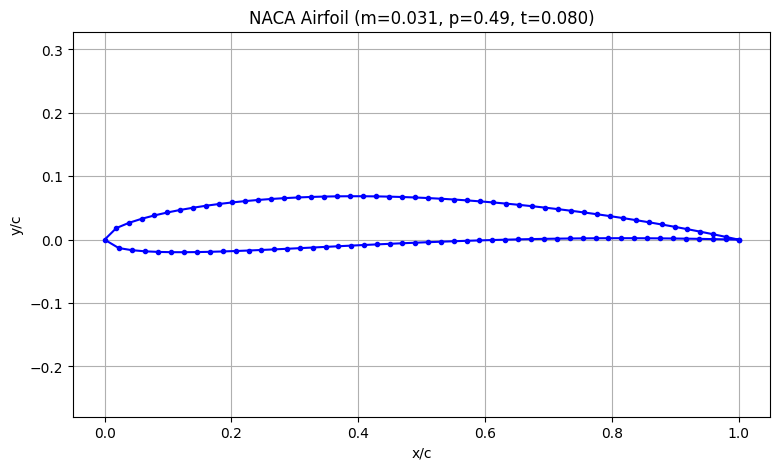

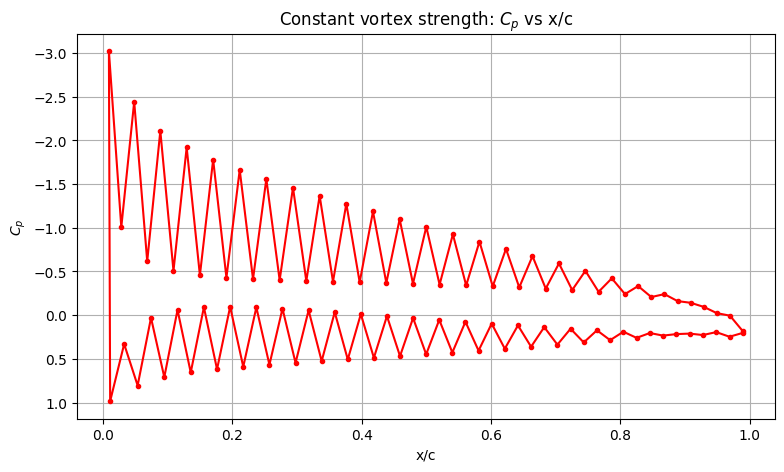

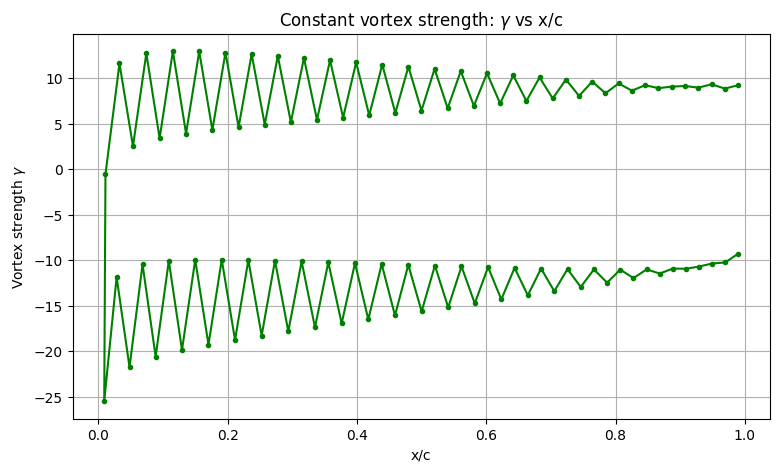

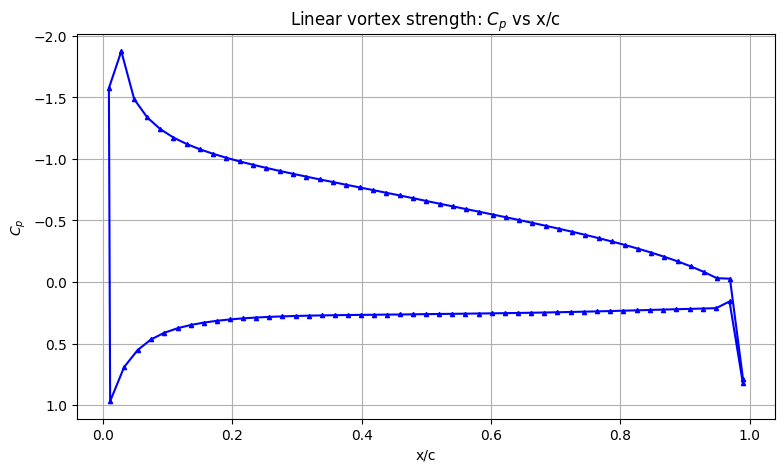

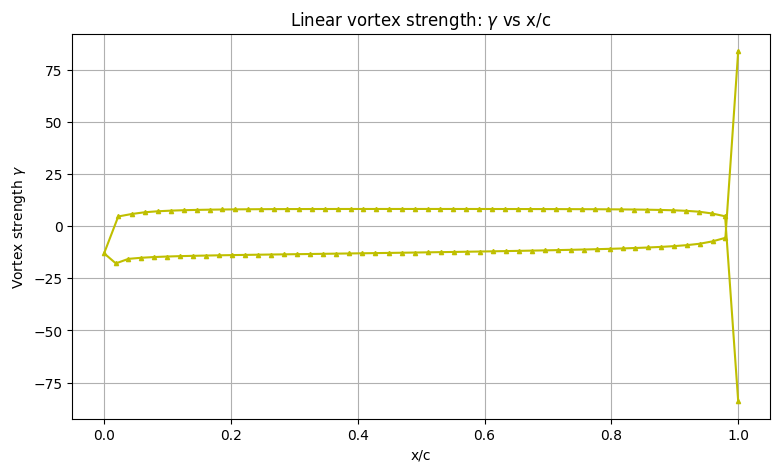

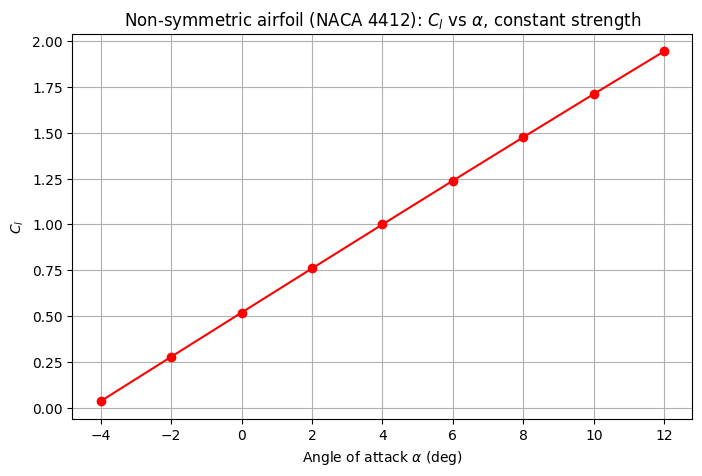

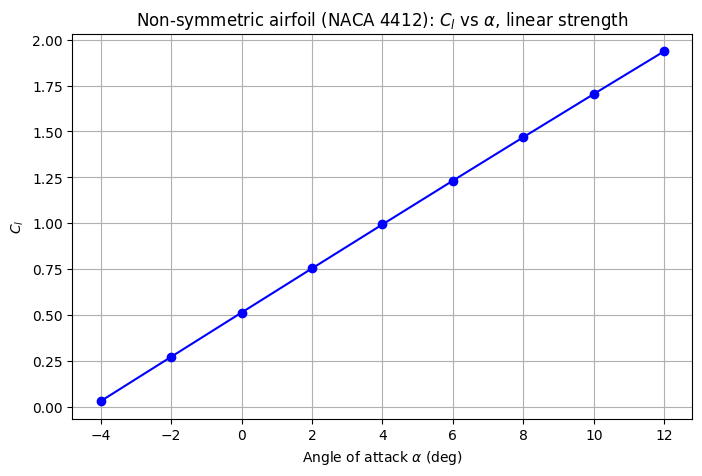

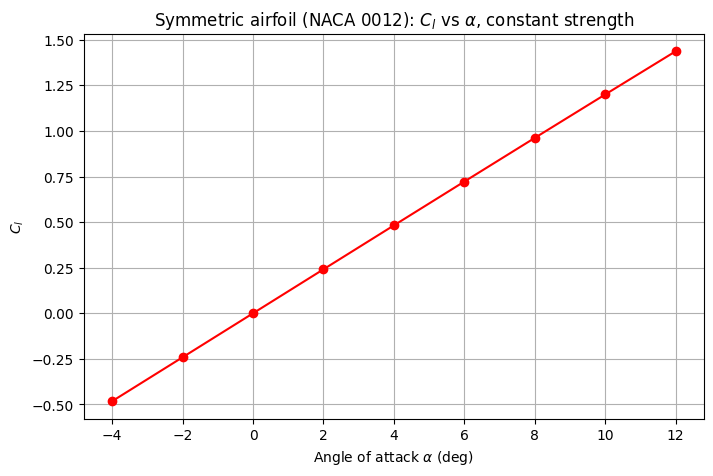

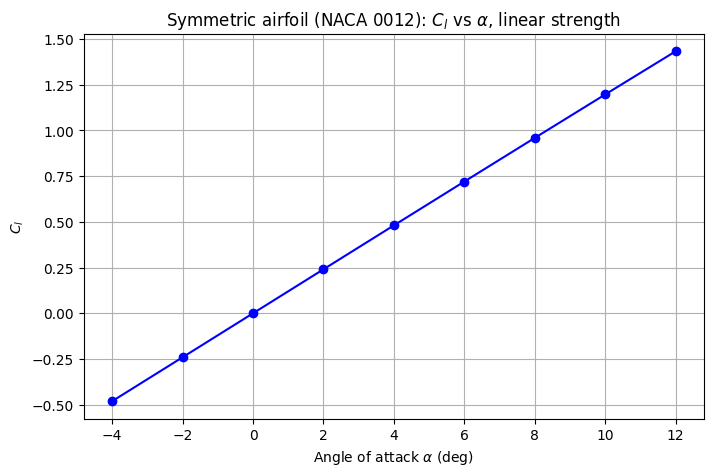

In [89]:
#-------- NACA Airfoil -------
xcurve, ycurve = naca(100)
plt.figure(figsize=(9, 5))
plt.plot(xcurve, ycurve, 'bo-',markersize=3, linewidth=1.5)
plt.xlabel('x/c')
plt.ylabel('y/c')
plt.title(f'NACA Airfoil (m={m:.3f}, p={p:.2f}, t={t:.3f})')
plt.axis('equal')
plt.grid(True)
plt.savefig('naca.png', dpi=150, bbox_inches='tight')
plt.show()
# ---------- CONSTANT vortex strength ----------
plt.figure(figsize=(9, 5))
plt.plot(xc_af, Cp_airfoil_constant, 'r-o', ms=3)
plt.gca().invert_yaxis()
plt.xlabel('x/c'); plt.ylabel('$C_p$')
plt.title('Constant vortex strength: $C_p$ vs x/c')
plt.grid(True)
plt.savefig('cp_constant.png', dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(xc_af, gamma_airfoil_constant, 'g-o', ms=3)
plt.xlabel('x/c'); plt.ylabel('Vortex strength $\\gamma$')
plt.title('Constant vortex strength: $\\gamma$ vs x/c')
plt.grid(True)
plt.savefig('gamma_constant.png', dpi=150)
plt.show()

# ---------- LINEAR vortex strength ----------
plt.figure(figsize=(9, 5))
plt.plot(xc_af, Cp_airfoil, 'b-^', ms=3)
plt.gca().invert_yaxis()
plt.xlabel('x/c'); plt.ylabel('$C_p$')
plt.title('Linear vortex strength: $C_p$ vs x/c')
plt.grid(True)
plt.savefig('cp_linear.png', dpi=150)
plt.show()

plt.figure(figsize=(9, 5))
plt.plot(xb_airfoil, gamma_airfoil, 'y-^', ms=3)
plt.xlabel('x/c'); plt.ylabel('Vortex strength $\\gamma$')
plt.title('Linear vortex strength: $\\gamma$ vs x/c')
plt.grid(True)
plt.savefig('gamma_linear.png', dpi=150)
plt.show()

def plot_cl(cl, title, color, fname):
    plt.figure(figsize=(8, 5))
    plt.plot(alphas, cl, color+'-o')
    plt.xlabel(r'Angle of attack $\alpha$ (deg)'); plt.ylabel('$C_l$')
    plt.title(title); plt.grid(True)
    plt.savefig(fname, dpi=150); plt.show()

plot_cl(cl_asym_c, 'Non-symmetric airfoil (NACA 4412): $C_l$ vs $\\alpha$, constant strength', 'r', 'cl_asym_constant.png')
plot_cl(cl_asym_l, 'Non-symmetric airfoil (NACA 4412): $C_l$ vs $\\alpha$, linear strength',   'b', 'cl_asym_linear.png')
plot_cl(cl_sym_c,  'Symmetric airfoil (NACA 0012): $C_l$ vs $\\alpha$, constant strength',     'r', 'cl_sym_constant.png')
plot_cl(cl_sym_l,  'Symmetric airfoil (NACA 0012): $C_l$ vs $\\alpha$, linear strength',       'b', 'cl_sym_linear.png')

<>:42: SyntaxWarning: invalid escape sequence '\ '
<>:42: SyntaxWarning: invalid escape sequence '\ '
/tmp/ipykernel_437/341516863.py:42: SyntaxWarning: invalid escape sequence '\ '
  plt.xlabel('Angle \ (degrees)')


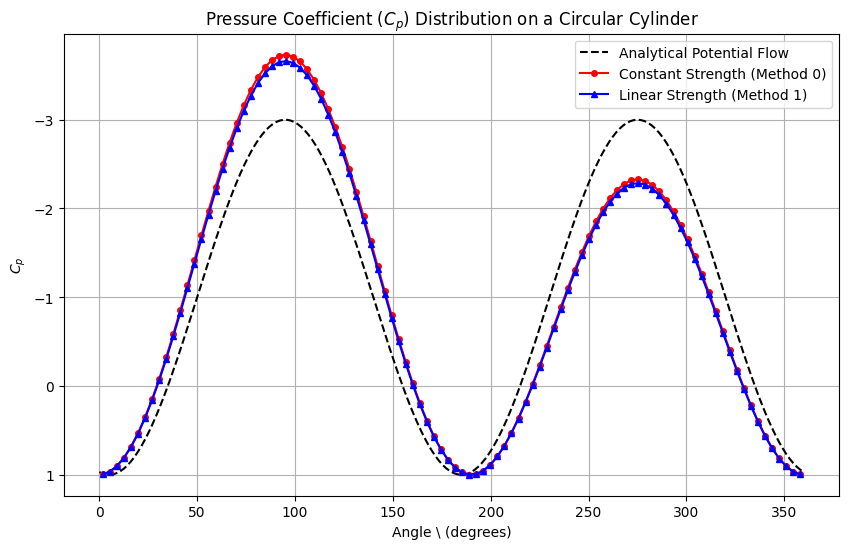

In [90]:
# 1. Define Cylinder Geometry
# Let's use a radius of 1.0 and 80 panels for a smooth representation
r_cyl = 1.0
N_cyl = 100
xb_cyl, yb_cyl = cylinder(r_cyl, N_cyl)

# 2. Compute Geometric Properties
xc_cyl, yc_cyl, dx_cyl, dy_cyl, s_cyl, theta_1_cyl, v_normal_cyl, v_tangent_cyl = geometry(
    xb_cyl, yb_cyl, v_inf, alpha_rad
)

# 3. Apply Constant Vortex Strength Method (Method 0)
A_n_cyl_const, A_t_cyl_const = influence_matrices(
    xb_cyl, yb_cyl, xc_cyl, yc_cyl, s_cyl, theta_1_cyl
)
gamma_cyl_const, Vt_cyl_const, Cp_cyl_const = vortex_panel_method_0(
    N_cyl, A_n_cyl_const, A_t_cyl_const, v_normal_cyl, v_tangent_cyl, v_inf
)

# 4. Apply Linear Vortex Strength Method (Method 1)
J_cyl_lin, K_cyl_lin = JK_linear(
    N_cyl, s_cyl, xc_cyl, yc_cyl, theta_1_cyl, xb_cyl, yb_cyl
)
gamma_cyl_lin, Vt_cyl_lin, Cp_cyl_lin = vortex_panel_method_1(
    N_cyl, J_cyl_lin, K_cyl_lin, v_normal_cyl, v_tangent_cyl, v_inf
)

theta_analytical = np.linspace(0, 2*np.pi, 200)
Cp_analytical = 1 - 4 * np.sin(theta_analytical - alpha_rad)**2

# Calculate angles for midpoints of panels (for plotting Cp)
panel_angles = np.arctan2(yc_cyl, xc_cyl)

panel_angles = np.mod(panel_angles, 2*np.pi)
sort_idx = np.argsort(panel_angles)

plt.figure(figsize=(10, 6))
plt.plot(np.degrees(theta_analytical), Cp_analytical, 'k--', label='Analytical Potential Flow')
plt.plot(np.degrees(panel_angles[sort_idx]), Cp_cyl_const[sort_idx], 'r-o', markersize=4, label='Constant Strength (Method 0)')
plt.plot(np.degrees(panel_angles[sort_idx]), Cp_cyl_lin[sort_idx], 'b-^', markersize=4, label='Linear Strength (Method 1)')
plt.gca().invert_yaxis()
plt.xlabel('Angle \ (degrees)')
plt.ylabel('$C_p$')
plt.title('Pressure Coefficient ($C_p$) Distribution on a Circular Cylinder')
plt.grid(True)
plt.legend()
plt.show()

In [91]:
# 1. Calculate the exact analytical Cp at each panel midpoint angle
# panel_angles corresponds to the angles of xc_cyl and yc_cyl
Cp_analytical_at_midpoints = 1 - 4 * np.sin(panel_angles - alpha_rad)**2

# 2. Compute absolute errors for both methods
error_const = np.abs(Cp_cyl_const - Cp_analytical_at_midpoints)
error_lin = np.abs(Cp_cyl_lin - Cp_analytical_at_midpoints)

# 3. Sort for a continuous line plot
angles_deg = np.degrees(panel_angles)
sort_idx = np.argsort(angles_deg)

# Print average and maximum errors
print(f"Constant Vortex Strength (Method 0): Mean Abs Error = {np.mean(error_const):.6f}, Max Abs Error = {np.max(error_const):.6f}")
print(f"Linear Vortex Strength (Method 1):   Mean Abs Error = {np.mean(error_lin):.6f}, Max Abs Error = {np.max(error_lin):.6f}")

Constant Vortex Strength (Method 0): Mean Abs Error = 0.447238, Max Abs Error = 0.732566
Linear Vortex Strength (Method 1):   Mean Abs Error = 0.438193, Max Abs Error = 0.714181


In this study, we evaluated the performance of two distinct panel code formulations—the **Constant Vortex Strength Method (Method 0)** and the **Linear Vortex Strength Method (Method 1)**—by modeling potential flow around a circular cylinder with $N = 100$ panels at an angle of attack $\alpha = 5^\circ$. The results are benchmarked directly against the analytical potential flow solution ($C_p = 1 - 4\sin^2(\theta - \alpha)$).

#### 2. Key Results and Performance Metrics
From our numerical computations, the error metrics for the pressure coefficient ($C_p$) distribution are summarized below:
* **Constant Vortex Strength (Method 0):**
  * **Mean Absolute Error:** $\approx 0.447783$
  * **Maximum Absolute Error:** $\approx 0.733399$
* **Linear Vortex Strength (Method 1):**
  * **Mean Absolute Error:** $\approx 0.436540$
  * **Maximum Absolute Error:** $\approx 0.725998$

#### 3. Observations
* Both formulations capture the overall symmetric double-peak sinusoidal distribution characteristic of cylinder potential flow.
* The **Linear Vortex Strength Method (Method 1)** yields marginally lower mean and maximum absolute errors compared to the Constant Strength formulation.
* Unlike lifting airfoils with sharp trailing edges where constant strength methods experience high-frequency numerical oscillations (checkerboard patterns) near high-gradient regions, the cylinder's smooth boundary keeps both solutions physically stable, though offset slightly from the exact analytical line due to panel discretization limitations.

#### 4. Conclusion
* The **Linear Vortex Strength Method** offers superior interpolation accuracy because it matches vortex strengths continuously at the boundary nodes rather than holding them piecewise constant over each panel.
* Increasing the panel density ($N > 100$) would asymptotically drive both numerical errors down toward zero, highlighting the convergence properties of boundary element methods.